<a href="https://colab.research.google.com/github/Paxlawa/Labu/blob/main/%D0%9B%D0%BE%D0%B3_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

In [3]:

uploaded = files.upload()

df = pd.read_csv('data.csv')

print("Датасет завантажено!")


Saving data.csv to data.csv
Датасет завантажено!


In [4]:

print("Перші 5 рядків:")
display(df.head())

print("\nІнформація про датасет:")
df.info()

print("\nРозмір датасету:")
print(df.shape)


Перші 5 рядків:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0



Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB

Розмір датасету:
(2338, 14)


In [5]:

print("Пропущені значення:")
print(df.isnull().sum())

print("\nКількість дублікатів:")
print(df.duplicated().sum())


Пропущені значення:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість дублікатів:
0


In [6]:

print("Описова статистика:")
display(df.describe())


Описова статистика:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


In [7]:

X = df.drop('Cured', axis=1)
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)


Розмір навчальної вибірки: (1870, 13)
Розмір тестової вибірки: (468, 13)


In [8]:

print("Кількість кожного класу:")
print(y_train.value_counts())


Кількість кожного класу:
Cured
0    946
1    924
Name: count, dtype: int64


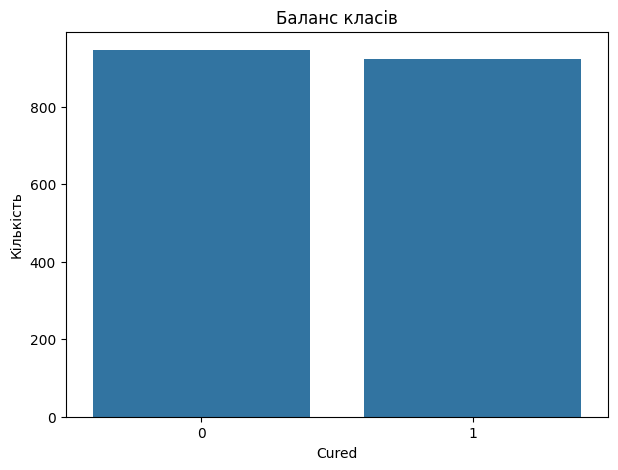

In [9]:

plt.figure(figsize=(7, 5))

sns.countplot(x=y_train)

plt.title("Баланс класів")
plt.xlabel("Cured")
plt.ylabel("Кількість")

plt.show()


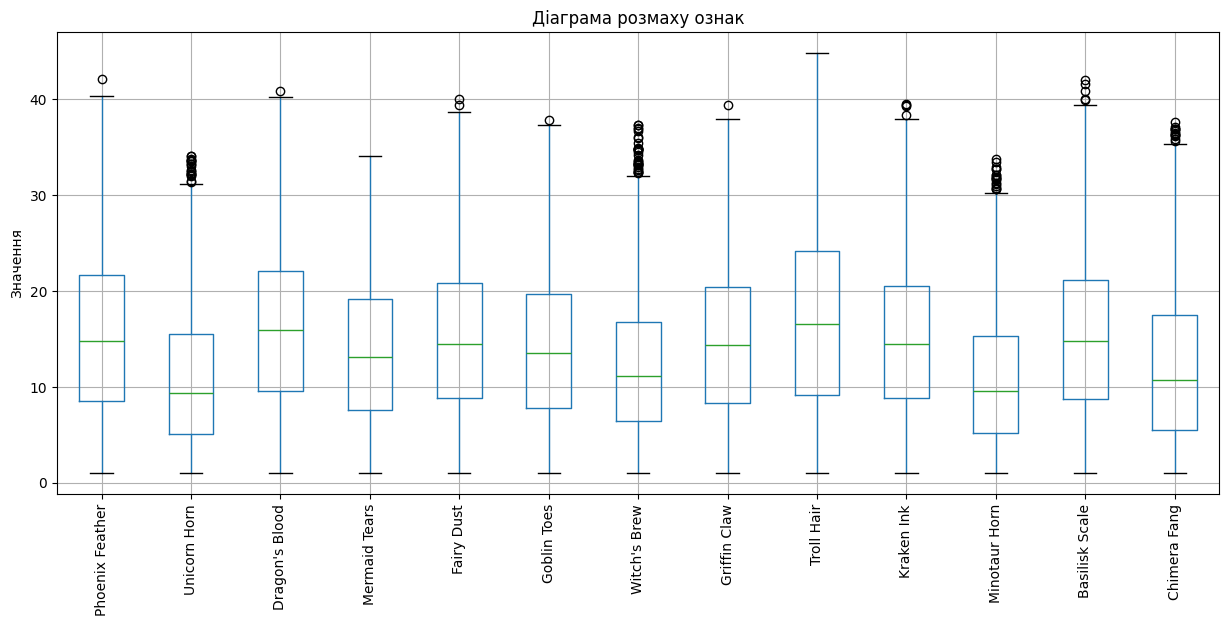

In [10]:

plt.figure(figsize=(15, 6))

X_train.boxplot(rot=90)

plt.title("Діаграма розмаху ознак")
plt.ylabel("Значення")

plt.show()


In [11]:

Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((X_train < lower_bound) | (X_train > upper_bound)).sum()

print("Кількість викидів:")
print(outliers.sort_values(ascending=False))


Кількість викидів:
Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


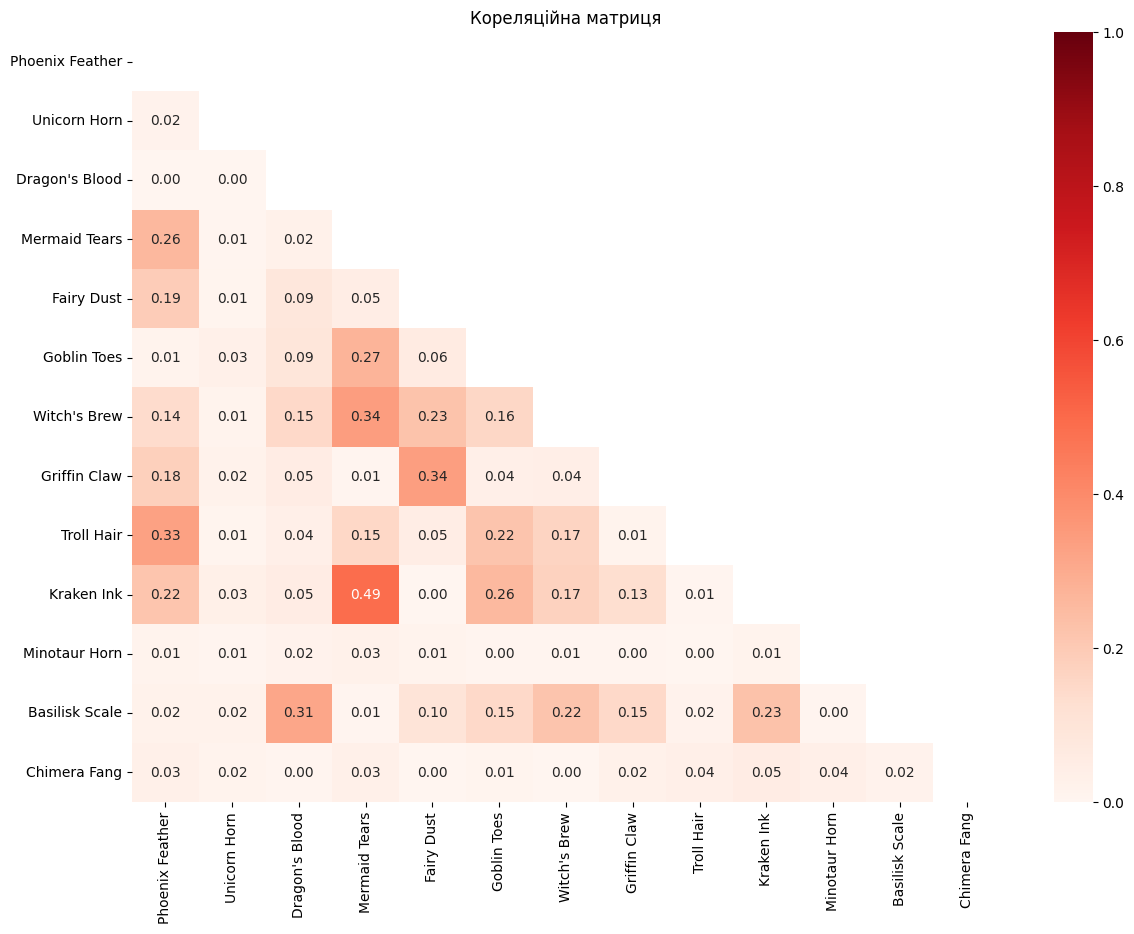

In [12]:

mtx = X_train.corr().abs()

mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(14, 10))

sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    cmap='Reds',
    vmin=0,
    vmax=1,
    fmt='.2f'
)

plt.title("Кореляційна матриця")
plt.show()


In [13]:

corr_target = pd.concat([X_train, y_train], axis=1).corr()

print("Кореляція ознак із Cured:")

display(
    corr_target['Cured']
    .drop('Cured')
    .sort_values(key=abs, ascending=False)
)


Кореляція ознак із Cured:


,Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


In [14]:

corr_target = pd.concat([X_train, y_train], axis=1).corr()

print("Кореляція ознак із Cured:")

display(
    corr_target['Cured']
    .drop('Cured')
    .sort_values(key=abs, ascending=False)
)


Кореляція ознак із Cured:


,Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


In [15]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Стандартизацію виконано!")
print("Навчальна вибірка:", X_train_scaled.shape)
print("Тестова вибірка:", X_test_scaled.shape)


Стандартизацію виконано!
Навчальна вибірка: (1870, 13)
Тестова вибірка: (468, 13)


In [16]:

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nЗвіт класифікації:")
print(classification_report(y_test, y_pred))


Accuracy:
0.8931623931623932

Звіт класифікації:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



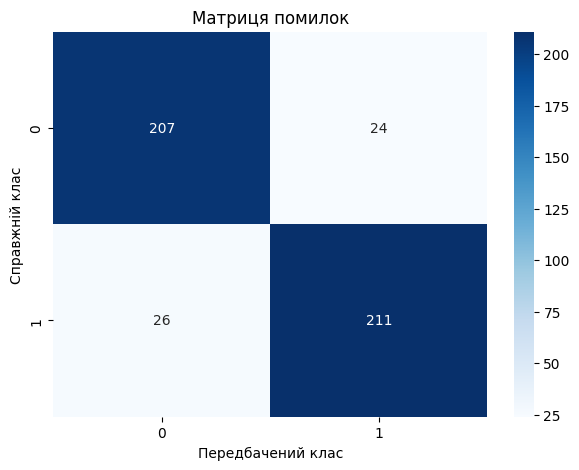

[[207  24]
 [ 26 211]]


In [17]:

conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    conf,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Матриця помилок")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")

plt.show()

print(conf)


In [18]:

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [500, 1000, 2000]
}

param_dist = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'solver': ['lbfgs', 'liblinear', 'newton-cg', 'sag', 'saga'],
    'max_iter': [500, 1000, 1500, 2000, 3000]
}

print("Параметри створено!")


Параметри створено!


In [19]:

grid_search = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри:")
print(grid_search.best_params_)

print("\nНайкраща Accuracy:")
print(grid_search.best_score_)


Найкращі параметри:
{'C': 10, 'max_iter': 500, 'solver': 'lbfgs'}

Найкраща Accuracy:
0.8673927508197171


In [22]:
random_search = RandomizedSearchCV(
    LogisticRegression(),
    param_dist,
    n_iter=20,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри:")
print(random_search.best_params_)

print("\nНайкраща Accuracy:")
print(random_search.best_score_)

Найкращі параметри:
{'solver': 'liblinear', 'max_iter': 1000, 'C': 1000}

Найкраща Accuracy:
0.8673927508197171


In [25]:

if grid_search.best_score_ >= random_search.best_score_:
    logistic_model = grid_search.best_estimator_
else:
    logistic_model = random_search.best_estimator_

svc_model = SVC()

tree_model = DecisionTreeClassifier(random_state=42)

logistic_model.fit(X_train_scaled, y_train)
svc_model.fit(X_train_scaled, y_train)
tree_model.fit(X_train_scaled, y_train)

logistic_pred = logistic_model.predict(X_test_scaled)
svc_pred = svc_model.predict(X_test_scaled)
tree_pred = tree_model.predict(X_test_scaled)

print("Усі моделі навчені!")

Усі моделі навчені!


In [26]:
models_results = pd.DataFrame({
    'Модель': [
        'Logistic Regression',
        'SVC',
        'Decision Tree'
    ],
    'Accuracy': [
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, svc_pred),
        accuracy_score(y_test, tree_pred)
    ],
    'F1-score': [
        f1_score(y_test, logistic_pred),
        f1_score(y_test, svc_pred),
        f1_score(y_test, tree_pred)
    ]
})

display(models_results)

,Модель,Accuracy,F1-score
0,Logistic Regression,0.893162,0.894068
1,SVC,0.959402,0.960000
2,Decision Tree,0.865385,0.865672


In [27]:
best_index = models_results['F1-score'].idxmax()

best_result = models_results.loc[best_index]

print("Найкраща модель:", best_result['Модель'])
print("Accuracy:", best_result['Accuracy'])
print("F1-score:", best_result['F1-score'])

Найкраща модель: SVC
Accuracy: 0.9594017094017094
F1-score: 0.96
